In [31]:
 
# ============================================================
# ECONOCASUAL PROJECT: EXPLORATORY DATA ANALYSIS (EDA)
# Dataset: Retail_synthetic_dataset.csv
# ============================================================

# 1. LOAD DATASET
# ------------------------------------------------------------

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_path = Path.cwd().parent
file_path = (project_path / "data" / "raw" /"Retail_synthetic_dataset.csv")

df = pd.read_csv(file_path)

print("DATASET LOADED SUCCESSFULLY")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

DATASET LOADED SUCCESSFULLY
Rows: 64000
Columns: 23


,user_id,age_group,income_bracket,region_type,is_new_customer,purchase_channel,buys_mens,buys_womens,months_since_last_purchase,past_spend,past_spend_tier,site_visits_90d,loyalty_score,coupon_usage_rate,discount_amount,purchased,spend_amount,true_p_buy_0,true_p_buy_10,true_p_buy_20,true_ite_10,true_ite_20,true_customer_type
0,1,18-25,3,Suburban,0,Phone,1,0,10,142.44,2) $100 - $200,0,7.1,0.195,10,0,0.0,0.0199,0.0499,0.0710,0.0300,0.0511,Lost Cause
1,2,26-35,5,Rural,1,Web,1,1,6,329.08,3) $200 - $350,2,42.7,0.436,10,0,0.0,0.0955,0.1834,0.2285,0.0878,0.1330,Persuadable
2,3,56-70,6,Suburban,1,Web,0,1,7,180.65,2) $100 - $200,5,31.0,0.164,10,0,0.0,0.0771,0.1323,0.1571,0.0552,0.0801,Persuadable
3,4,18-25,7,Rural,1,Web,1,0,9,675.83,5) $500 - $750,3,49.4,0.081,0,0,0.0,0.1407,0.1092,0.0876,-0.0315,-0.0531,Sleeping Dog
4,5,56-70,5,Urban,0,Web,1,0,2,45.34,1) $0 - $100,3,49.3,0.369,0,0,0.0,0.0835,0.1521,0.1854,0.0685,0.1019,Persuadable


In [36]:
# 2. DATA QUALITY CHECKS
# ------------------------------------------------------------

print("\n--- DATA QUALITY ---")

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique customers:", df["user_id"].nunique())

print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))


--- DATA QUALITY ---
Missing values: 0
Duplicate rows: 0
Unique customers: 64000

Missing values by column:


user_id                       0
age_group                     0
income_bracket                0
region_type                   0
is_new_customer               0
purchase_channel              0
buys_mens                     0
buys_womens                   0
months_since_last_purchase    0
past_spend                    0
past_spend_tier               0
site_visits_90d               0
loyalty_score                 0
coupon_usage_rate             0
discount_amount               0
purchased                     0
spend_amount                  0
true_p_buy_0                  0
true_p_buy_10                 0
true_p_buy_20                 0
true_ite_10                   0
true_ite_20                   0
true_customer_type            0
dtype: int64


Data types:


,Data Type
user_id,int64
age_group,str
income_bracket,int64
region_type,str
is_new_customer,int64
purchase_channel,str
buys_mens,int64
buys_womens,int64
months_since_last_purchase,int64
past_spend,float64


In [40]:
# 3. NUMERICAL DATA SUMMARY
# ------------------------------------------------------------

print("\n--- NUMERICAL SUMMARY ---")

display(df.describe(include="number").T)





--- NUMERICAL SUMMARY ---


,count,mean,std,min,25%,50%,75%,max
user_id,64000.0,32000.500000,18475.352951,1.0000,16000.7500,32000.5000,48000.250000,64000.0000
income_bracket,64000.0,4.711375,2.248602,1.0000,3.0000,5.0000,6.000000,12.0000
is_new_customer,64000.0,0.502250,0.499999,0.0000,0.0000,1.0000,1.000000,1.0000
buys_mens,64000.0,0.551031,0.497393,0.0000,0.0000,1.0000,1.000000,1.0000
buys_womens,64000.0,0.549719,0.497526,0.0000,0.0000,1.0000,1.000000,1.0000
months_since_last_purchase,64000.0,5.763734,3.507592,1.0000,2.0000,6.0000,9.000000,12.0000
past_spend,64000.0,242.085656,256.158608,29.9900,64.6600,158.1100,325.657500,3345.9300
site_visits_90d,64000.0,3.031859,2.266706,0.0000,1.0000,3.0000,4.000000,20.0000
loyalty_score,64000.0,50.038778,23.681316,0.8000,30.7000,50.2000,69.300000,99.1000
coupon_usage_rate,64000.0,0.325397,0.178390,0.0080,0.1840,0.2980,0.443000,0.9470


In [44]:

# 4. CATEGORICAL DATA SUMMARY
# ------------------------------------------------------------

print("\n--- CATEGORICAL SUMMARY ---")

display(df.describe(include=["object", "category"]).T)

print("\nCustomer categories:")

for col in [
    "age_group",
    "income_bracket",
    "region_type",
    "purchase_channel",
    "true_customer_type"
]:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))


--- CATEGORICAL SUMMARY ---


C:\Users\srikr\AppData\Local\Temp\ipykernel_20224\4165134817.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=["object", "category"]).T)


,count,unique,top,freq
age_group,64000,6,46-55,22779
region_type,64000,3,Suburban,28776
purchase_channel,64000,3,Web,28217
past_spend_tier,64000,7,1) $0 - $100,22970
true_customer_type,64000,4,Persuadable,27038



Customer categories:

age_group
age_group
46-55    22779
36-45    15827
26-35    11062
70+       5702
56-70     4769
18-25     3861
Name: count, dtype: int64

income_bracket
income_bracket
5     15736
4     13815
6      7472
3      6009
2      5696
1      4955
8      3101
7      2731
9      2405
10      874
12      806
11      400
Name: count, dtype: int64

region_type
region_type
Suburban    28776
Urban       25661
Rural        9563
Name: count, dtype: int64

purchase_channel
purchase_channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

true_customer_type
true_customer_type
Persuadable     27038
Lost Cause      16986
Sleeping Dog    14565
Sure Thing       5411
Name: count, dtype: int64


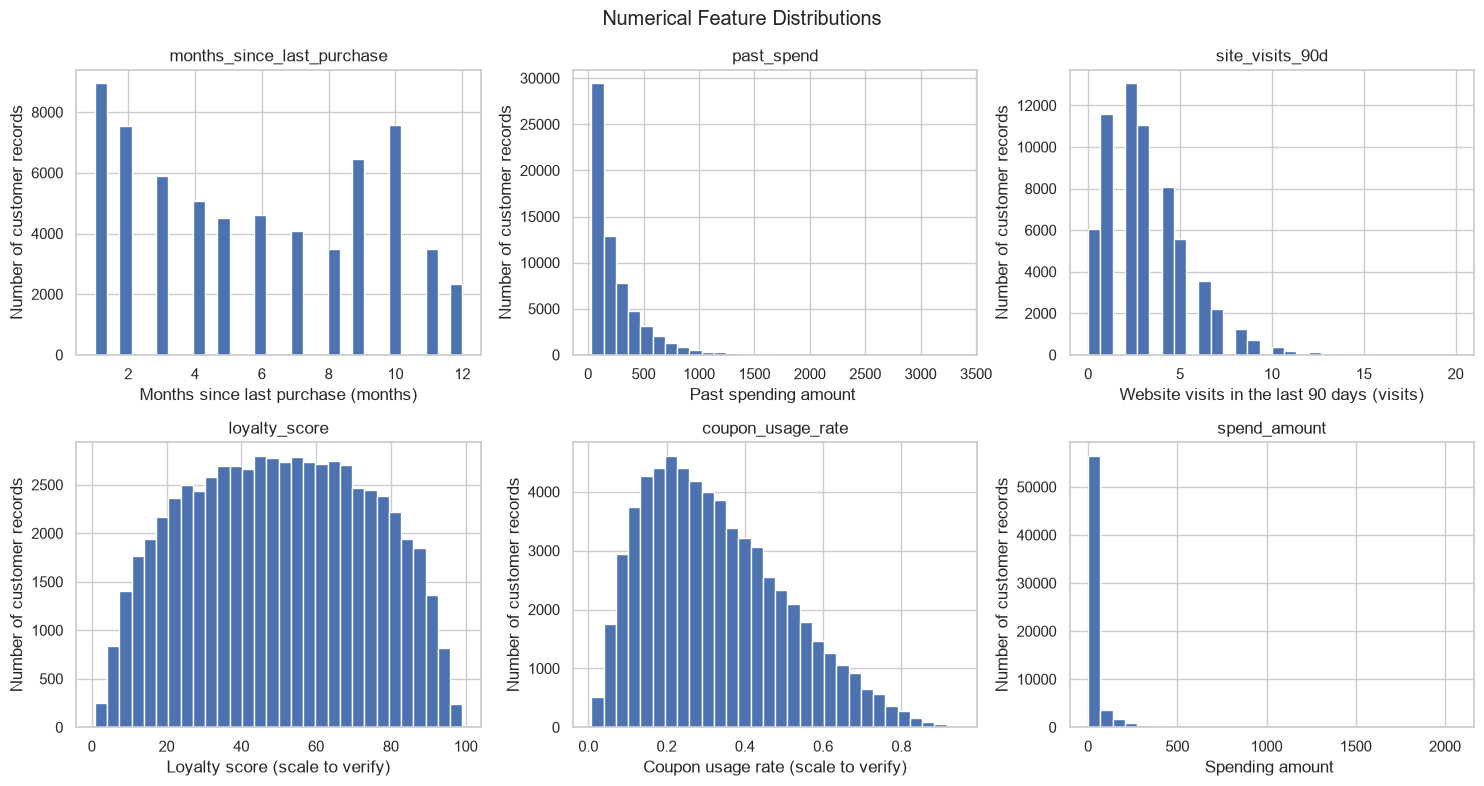

In [47]:
# 5. NUMERICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

# Currency is not assumed because its unit is unconfirmed.
numeric_plots = {
    "months_since_last_purchase":
        "Months since last purchase (months)",

    "past_spend":
        "Past spending amount ",

    "site_visits_90d":
        "Website visits in the last 90 days (visits)",

    "loyalty_score":
        "Loyalty score (scale to verify)",

    "coupon_usage_rate":
        "Coupon usage rate (scale to verify)",

    "spend_amount":
        "Spending amount "
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (col, label) in zip(axes.flatten(), numeric_plots.items()):
    df[col].dropna().hist(bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of customer records")

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


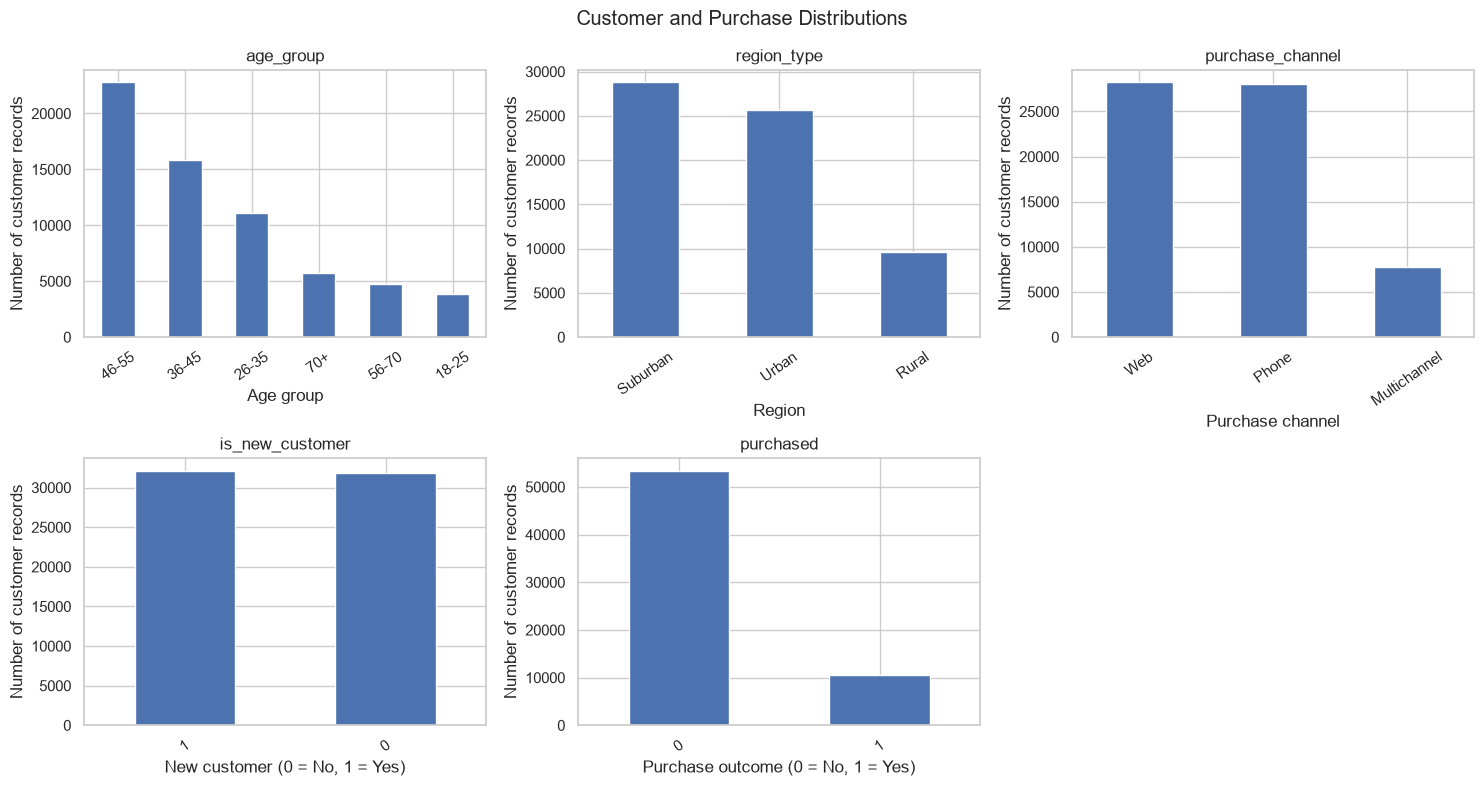

In [19]:
# 6. CUSTOMER GROUP DISTRIBUTIONS
# ------------------------------------------------------------

group_columns = {
    "age_group": "Age group",
    "region_type": "Region",
    "purchase_channel": "Purchase channel",
    "is_new_customer": "New customer (0 = No, 1 = Yes)",
    "purchased": "Purchase outcome (0 = No, 1 = Yes)"
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (col, label) in zip(axes, group_columns.items()):
    counts = df[col].value_counts(dropna=False)
    counts.plot(kind="bar", ax=ax)

    ax.set_title(col)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of customer records")
    ax.tick_params(axis="x", rotation=35)

# Hide unused subplot
for ax in axes[len(group_columns):]:
    ax.set_visible(False)

plt.suptitle("Customer and Purchase Distributions")
plt.tight_layout()
plt.show()



--- RECORDS BY DISCOUNT ---


,Customer records
discount_amount,
0,24200
10,22723
20,17077


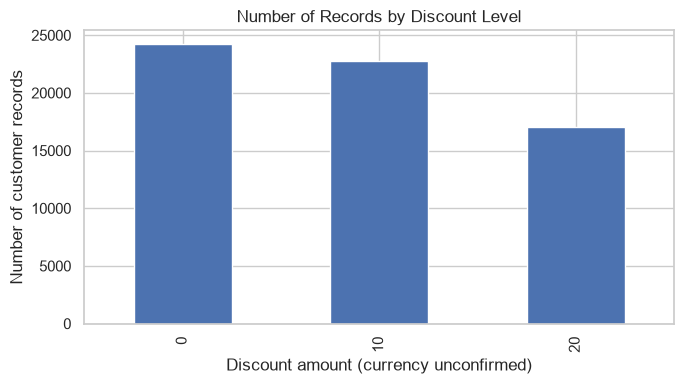

In [20]:
# 7. DISCOUNT DISTRIBUTION
# ------------------------------------------------------------

print("\n--- RECORDS BY DISCOUNT ---")

discount_counts = (
    df["discount_amount"]
    .value_counts(dropna=False)
    .sort_index()
)

display(discount_counts.to_frame("Customer records"))

discount_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Number of Records by Discount Level")
plt.xlabel("Discount amount (currency unconfirmed)")
plt.ylabel("Number of customer records")
plt.tight_layout()
plt.show()

In [21]:
# 8. CUSTOMER CHARACTERISTICS BY DISCOUNT
# ------------------------------------------------------------

features = [
    "past_spend",
    "months_since_last_purchase",
    "site_visits_90d",
    "loyalty_score",
    "coupon_usage_rate"
]

print("\n--- AVERAGE CUSTOMER CHARACTERISTICS BY DISCOUNT ---")

group_means = (
    df.groupby("discount_amount")[features]
    .mean()
    .round(2)
)

display(group_means)

# Large differences can suggest that discount assignment
# is related to customer characteristics.
# This alone does not prove confounding or causation.


--- AVERAGE CUSTOMER CHARACTERISTICS BY DISCOUNT ---


,past_spend,months_since_last_purchase,site_visits_90d,loyalty_score,coupon_usage_rate
discount_amount,,,,,
0,239.69,4.70,3.43,55.18,0.29
10,246.02,6.09,2.90,48.34,0.34
20,240.25,6.84,2.65,45.02,0.36



--- PURCHASE RATE BY DISCOUNT ---


,Purchase rate (%)
discount_amount,
0,16.86
10,15.33
20,17.60


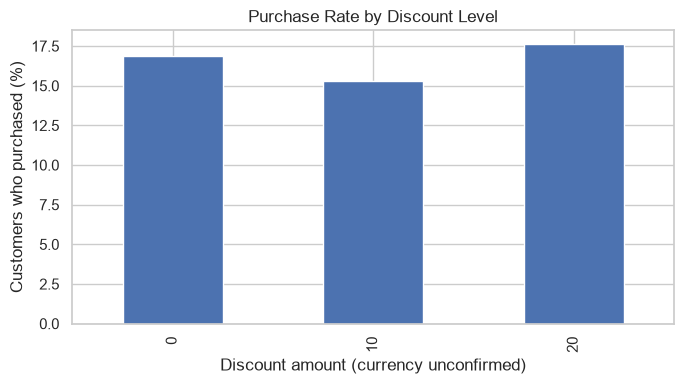

In [22]:
# 9. PURCHASE RATE BY DISCOUNT
# ------------------------------------------------------------

print("\n--- PURCHASE RATE BY DISCOUNT ---")

purchase_rate = (
    df.groupby("discount_amount")["purchased"]
    .mean()
    .mul(100)
)

display(purchase_rate.to_frame("Purchase rate (%)").round(2))

purchase_rate.plot(kind="bar", figsize=(7, 4))

plt.title("Purchase Rate by Discount Level")
plt.xlabel("Discount amount (currency unconfirmed)")
plt.ylabel("Customers who purchased (%)")
plt.tight_layout()
plt.show()



--- NAIVE VS TRUE EFFECT ---


,Comparison,Naive effect (percentage points),Synthetic true effect (percentage points),Absolute error (percentage points)
0,10 vs 0,-1.53,1.78,3.31
1,20 vs 0,0.75,3.01,2.26


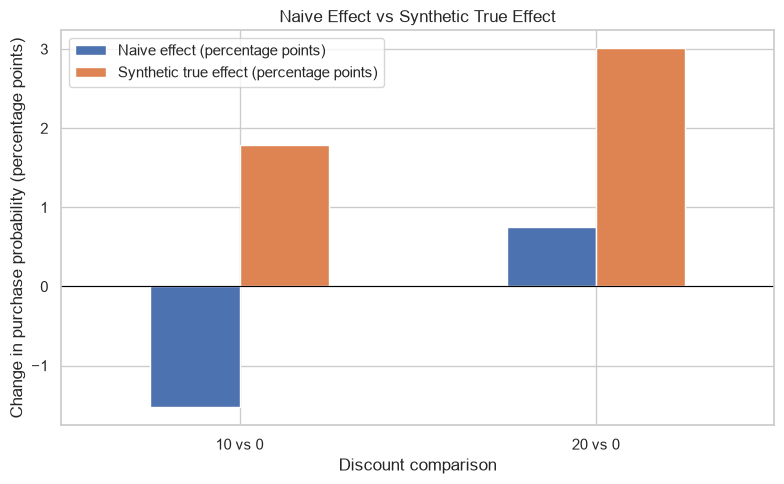

In [23]:
# 10. NAIVE EFFECT VS SYNTHETIC TRUE EFFECT
# ------------------------------------------------------------

# Naive effect = observed purchase-rate difference.
# True effect = average known synthetic probability difference.
# This assumes true_ite columns represent purchase-probability
# effects, measured as treated minus no-discount outcomes.

rates = df.groupby("discount_amount")["purchased"].mean()

results = []

for discount in [10, 20]:

    if 0 not in rates.index or discount not in rates.index:
        print(f"Cannot compare discount {discount} with 0.")
        continue

    naive_effect = (
        rates.loc[discount] - rates.loc[0]
    ) * 100

    true_col = f"true_ite_{discount}"

    if true_col not in df.columns:
        print(f"Missing column: {true_col}")
        continue

    true_effect = df[true_col].mean() * 100

    results.append({
        "Comparison": f"{discount} vs 0",
        "Naive effect (percentage points)": naive_effect,
        "Synthetic true effect (percentage points)": true_effect,
        "Absolute error (percentage points)": abs(
            naive_effect - true_effect
        )
    })

result = pd.DataFrame(results)

print("\n--- NAIVE VS TRUE EFFECT ---")
display(result.round(2))

if not result.empty:
    plot_data = result.set_index("Comparison")[
        [
            "Naive effect (percentage points)",
            "Synthetic true effect (percentage points)"
        ]
    ]

    ax = plot_data.plot(kind="bar", figsize=(8, 5), rot=0)
    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_xlabel("Discount comparison")
    ax.set_ylabel("Change in purchase probability (percentage points)")
    ax.set_title("Naive Effect vs Synthetic True Effect")

    plt.tight_layout()
    plt.show()



--- PURCHASE RATE BY LOYALTY GROUP AND DISCOUNT ---


discount_amount,0,10,20
loyalty_group,,,
Group 1,2.84,8.68,14.50
Group 2,6.93,11.88,16.69
Group 3,12.00,14.91,17.97
Group 4,17.85,18.55,18.45
Group 5,33.90,24.59,23.21


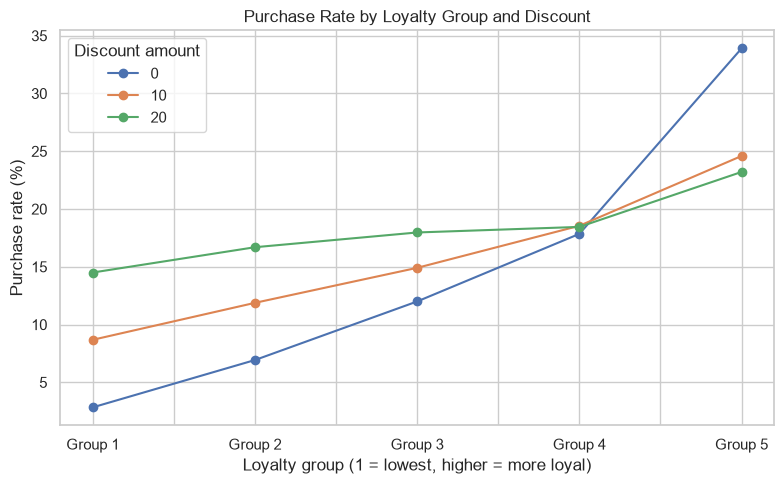

In [29]:
# 11. PURCHASE RATE BY LOYALTY GROUP
# ------------------------------------------------------------

# Split customers into five groups by loyalty score.
# qcut creates groups based on rank/quantiles.

df["loyalty_group"] = pd.qcut(
    df["loyalty_score"],
    q=5,
    labels=False,
    duplicates="drop"
)

df["loyalty_group"] = (
    df["loyalty_group"]
    .add(1)
    .map(lambda x: f"Group {int(x)}" if pd.notna(x) else "Missing")
)

print("\n--- PURCHASE RATE BY LOYALTY GROUP AND DISCOUNT ---")

loyalty_table = (
    df.pivot_table(
        index="loyalty_group",
        columns="discount_amount",
        values="purchased",
        aggfunc="mean",
        observed=True
    ) * 100
)

display(loyalty_table.round(2))

loyalty_table.plot(marker="o", figsize=(8, 5))

plt.xlabel("Loyalty group (1 = lowest, higher = more loyal)")
plt.ylabel("Purchase rate (%)")
plt.title("Purchase Rate by Loyalty Group and Discount")
plt.legend(title="Discount amount")
plt.tight_layout()
plt.show()



--- CUSTOMER TYPE DISTRIBUTION ---


,Share of records (%)
true_customer_type,
Persuadable,42.25
Lost Cause,26.54
Sleeping Dog,22.76
Sure Thing,8.45


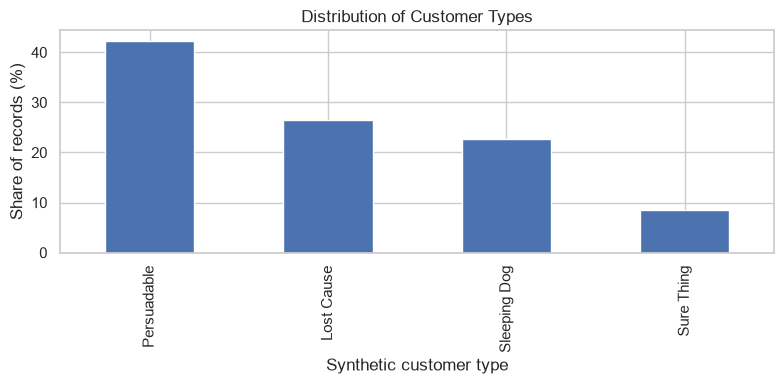


--- AVERAGE TRUE ITE BY CUSTOMER TYPE ---


,true_ite_10,true_ite_20
true_customer_type,,
Lost Cause,0.0169,0.0201
Persuadable,0.0835,0.1398
Sleeping Dog,-0.1017,-0.1524
Sure Thing,0.0144,0.0046


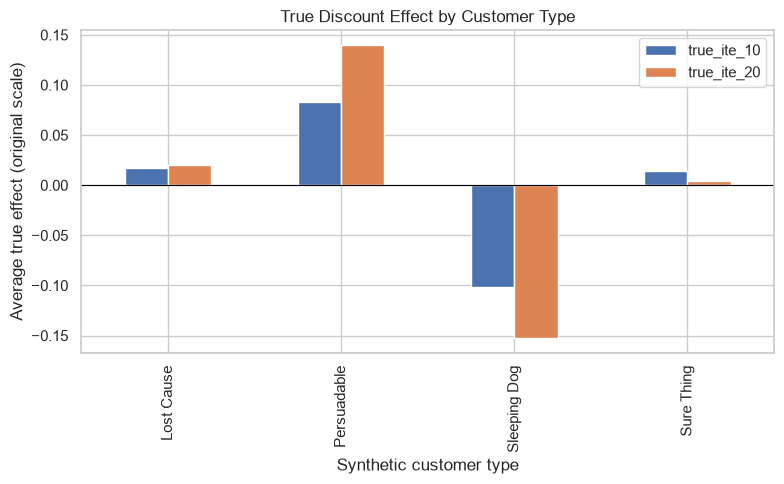

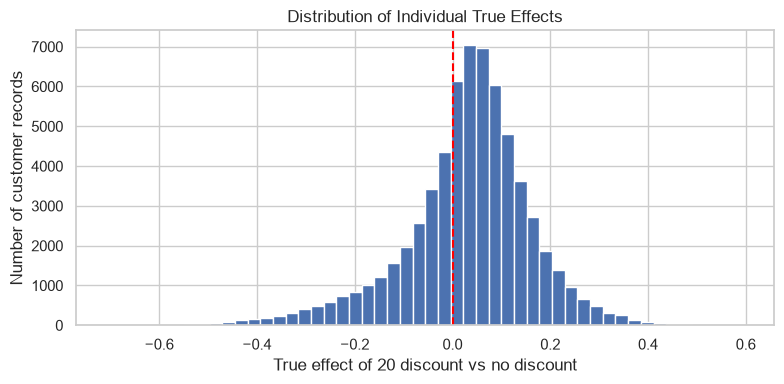

Records with negative true_ite_20 (%): 33.2


In [24]:
# 12. CUSTOMER TYPES AND TRUE ITE
# ------------------------------------------------------------

print("\n--- CUSTOMER TYPE DISTRIBUTION ---")

type_share = (
    df["true_customer_type"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

display(type_share.round(2).to_frame("Share of records (%)"))

type_share.plot(kind="bar", figsize=(8, 4))

plt.xlabel("Synthetic customer type")
plt.ylabel("Share of records (%)")
plt.title("Distribution of Customer Types")
plt.tight_layout()
plt.show()


# Average true effect for each customer type
ite_cols = ["true_ite_10", "true_ite_20"]

print("\n--- AVERAGE TRUE ITE BY CUSTOMER TYPE ---")

ite_by_type = (
    df.groupby("true_customer_type")[ite_cols]
    .mean()
)

display(ite_by_type.round(4))

ite_by_type.plot(kind="bar", figsize=(8, 5))

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Synthetic customer type")
plt.ylabel("Average true effect (original scale)")
plt.title("True Discount Effect by Customer Type")
plt.tight_layout()
plt.show()


# Individual effect distribution for the 20 discount level
plt.figure(figsize=(8, 4))

plt.hist(df["true_ite_20"].dropna(), bins=50)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("True effect of 20 discount vs no discount")
plt.ylabel("Number of customer records")
plt.title("Distribution of Individual True Effects")
plt.tight_layout()
plt.show()

print(
    "Records with negative true_ite_20 (%):",
    round((df["true_ite_20"] < 0).mean() * 100, 2)
)



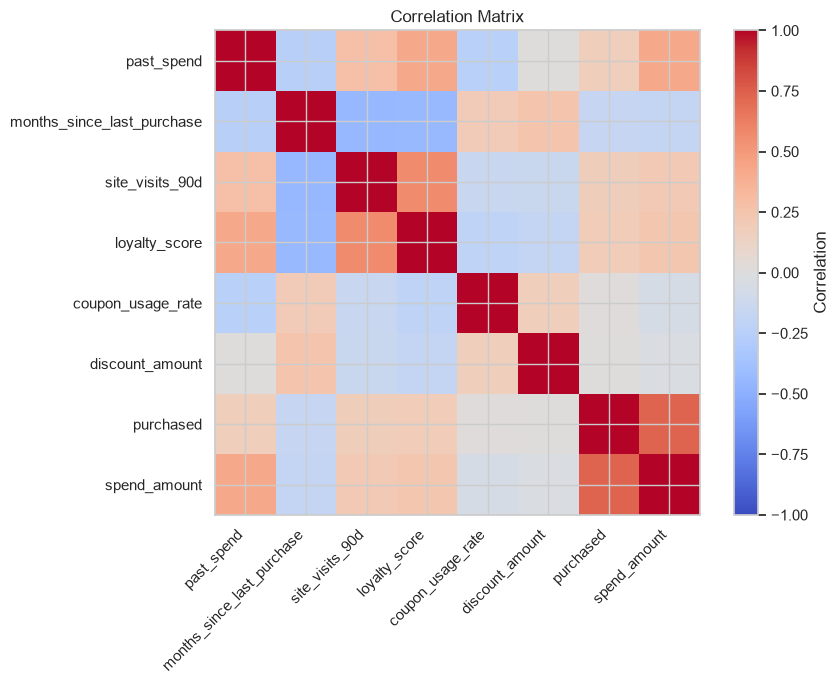

In [25]:
# 13. CORRELATION BETWEEN IMPORTANT NUMERICAL VARIABLES
# ------------------------------------------------------------

corr_cols = [
    "past_spend",
    "months_since_last_purchase",
    "site_visits_90d",
    "loyalty_score",
    "coupon_usage_rate",
    "discount_amount",
    "purchased",
    "spend_amount"
]

corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()



In [28]:
14. #FINAL PROJECT SUMMARY
# ------------------------------------------------------------

print("\n========== EDA SUMMARY ==========")

print("Total records:", len(df))
print("Unique customer IDs:", df["user_id"].nunique())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Overall purchase rate (%):", round(df["purchased"].mean() * 100, 2))

print("\nDiscount levels:")
print(sorted(df["discount_amount"].dropna().unique()))

print("\nEDA completed.")
print("Next step: train and evaluate a Double Machine Learning model.")


========== EDA SUMMARY ==========
Total records: 64000
Unique customer IDs: 64000
Missing values: 0
Duplicate rows: 0
Overall purchase rate (%): 16.51

Discount levels:
[np.int64(0), np.int64(10), np.int64(20)]

EDA completed.
Next step: train and evaluate a Double Machine Learning model.
